# Multilayer Perceptron from Scratch - XOR
## Introduction

A Multilayer Perceptron (MLP) is a type of feedforward artificial neural network that consists of an input layer, one or more hidden layers, and an output layer.

Unlike a single-layer perceptron, an MLP can learn complex, non-linear relationships between inputs and outputs using hidden layers and activation functions.

<div align="center">
  <img src="mlp.png" alt="mlp" />
</div>

## Objective

The main objective of this project is:
* To understand how a Multilayer Perceptron learns by implementing its fundamental operations manually.
* Solve the XOR (Exclusive OR) problem, which is a non-linearly separable problem.

## Implementation Workflow
* Weight and bias initialization.
* Forward propagation.
* Sigmoid activation function.
* Binary cross-entropy loss.
* Backpropagation.
* Gradient descent and parameter updates.

# Dataset Preparation
The dataset contains four input samples, each with two features, and one corresponding binary output.

The XOR gate produces an output of 1 when its two inputs are different and 0 when they are the same.

 Input $x_1$ | Input $x_2$ | Expected output $y$ |
|---:|---:|---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

The XOR dataset is not linearly separable, making it difficult to be trained using a perceptron.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
], dtype=float)

y = np.array([
    [0],
    [1],
    [1],
    [0]
], dtype=float)

print("Input shape:", X.shape)
print("Output shape:", y.shape)

print("\nInput data:")
print(X)

print("\nExpected output:")
print(y)

Input shape: (4, 2)
Output shape: (4, 1)

Input data:
[[0. 0.]
 [0. 1.]
 [1. 0.]
 [1. 1.]]

Expected output:
[[0.]
 [1.]
 [1.]
 [0.]]


# Mathematical Architecture

## 1. Architecture of a Multilayer Perceptron

The MLP implemented in this project follows a 2–4–1 architecture.

* Input layer: 2 neurons to receive the two input features.
* Hidden layer: 4 neurons to learn non-linear patterns.
* Output layer: 1 neuron to produce the predicted XOR output.
$$ \text{Input Layer} \rightarrow \text{Hidden Layer} \rightarrow \text{Output Layer} $$
$$ 2 \rightarrow 4 \rightarrow 1 $$

Parameter Dimension

$$ W_1 \in \mathbb{R}^{2\times4} $$
$$ b_1 \in \mathbb{R}^{1\times4} $$
$$ W_2 \in \mathbb{R}^{4\times1} $$
$$ b_2 \in \mathbb{R}^{1\times1} $$

The sigmoid activation function is used in both the hidden and output layers.

Sigmoid function

$$ \sigma(z)=\frac{1}{1+e^{-z}} $$

Sigmoid Derivative

$$ \sigma'(z)=\sigma(z)(1-\sigma(z)) $$

## 2. Methodology

The network follows these steps during training:

### 2.1 Weight and Bias Initialization

Weights are initialized using random values drawn from a normal distribution and scaled by 0.5. Biases are initialized to zero.

Weight Initialization
$$ W_1 \sim \mathcal{N}(0,1)\times 0.5 $$
$$ W_2 \sim \mathcal{N}(0,1)\times 0.5 $$

Bias Initalization
$$ b_1 = 0 $$
$$ b_2 = 0 $$

### 2.2 Forward Propagation

Input data is passed through the network to calculate the predicted output.

For the hidden layer:

$$ Z_1 = XW_1+b_1 $$
$$ A_1 = \sigma(Z_1) $$

For the output layer:

$$ Z_2 = A_1W_2+b_2 $$
$$ A_2 = \sigma(Z_2) $$

Predicted output:

$$
\hat{y}=A_2
$$


### 2.3 Loss Calculation

Binary Cross-Entropy (BCE) is used to measure the difference between the actual outputs and predicted probabilities.

The objective is to minimize this loss during training.

$$ L=-\frac{1}{m}\sum_{i=1}^{m}\left[y_i\log(\hat{y}_i)+(1-y_i)\log(1-\hat{y}_i)\right] $$

Prediction clipping

$$ \hat{y}_{\text{clipped}} = \min\left(1-\epsilon,\max(\epsilon,\hat{y})\right)
$$

$$ \epsilon=10^{-12} $$

### 2.4 Backpropagation

Backpropagation calculates the gradients of the loss with respect to the weights and biases.

These gradients are calculated starting from the output layer and propagated backward through the hidden layer.

Output Layer error
$$ dZ_2=\frac{A_2-y}{m} $$

Weight gradient

$$ dW_2=A_1^T dZ_2 $$

Bias gradient

$$
db_2=\sum_{i=1}^{m}dZ_2^{(i)}
$$

Hidden layer error propagation
* Gradient with respect to hidden activation:
  $$ dA_1=dZ_2W_2^T $$
* Gradient with respect to hidden weighted sum:
  $$ dZ_1=dA_1\odot A_1(1-A_1) $$
  
Hidden layer gradients
* Weight gradient:
  $$ dW_1=X^T dZ_1 $$
* Bias gradient:
  $$ db_1=\sum_{i=1}^{m}dZ_1^{(i)} $$

### 2.5 Gradient Descent

The calculated gradients are used to update the weights and biases.

The forward propagation, loss calculation, backpropagation, and parameter update steps are repeated for the specified number of epochs.

General weight update:

$$ W_{\text{new}}=W_{\text{old}}-\eta dW $$

General bias update:

$$ b_{\text{new}}=b_{\text{old}}-\eta db $$

Hidden layer updates:

$$ W_1=W_1-\eta dW_1 $$
$$ b_1=b_1-\eta db_1 $$

Output layer updates:

$$ W_2=W_2-\eta dW_2 $$
$$ b_2=b_2-\eta db_2 $$

# Implementation Details

The model was implemented using NumPy, with Matplotlib used to visualize the training loss.

 Parameter | Value |
|---:|---:|
| Network architecture | 2–4–1 |
| Hidden neurons | 4 |
| Activation function | Sigmoid |
| Loss function | Binary Cross-Entropy |
| Optimizer | Batch Gradient Descent |
| Learning rate | 0.1 |
| Number of epochs | 10,000 |
| Batch size | 4 |


In [2]:
# Set random seed for reproducibility
np.random.seed(42)

# Network architecture
input_neurons = 2
hidden_neurons = 4
output_neurons = 1

# Initialize weights
W1 = np.random.randn(input_neurons, hidden_neurons) * 0.5
W2 = np.random.randn(hidden_neurons, output_neurons) * 0.5

# Initialize biases
b1 = np.zeros((1, hidden_neurons))
b2 = np.zeros((1, output_neurons))

print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)
print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (2, 4)
b1 shape: (1, 4)
W2 shape: (4, 1)
b2 shape: (1, 1)


In [3]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [4]:
test_values = np.array([-5, -1, 0, 1, 5])

print("Input:", test_values)
print("Sigmoid:", sigmoid(test_values))

Input: [-5 -1  0  1  5]
Sigmoid: [0.00669285 0.26894142 0.5        0.73105858 0.99330715]


In [5]:
def forward_propagation(X, W1, b1, W2, b2):

    # Hidden layer
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    # Output layer
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2

In [6]:
Z1, A1, Z2, A2 = forward_propagation(X, W1, b1, W2, b2)

print("Hidden layer output:\n", A1)
print("\nNetwork predictions:\n", A2)

Hidden layer output:
 [[0.5        0.5        0.5        0.5       ]
 [0.47076421 0.47076626 0.68774681 0.59476937]
 [0.56177208 0.48272384 0.58026084 0.68168255]
 [0.53277304 0.45358387 0.75277186 0.758639  ]]

Network predictions:
 [[0.44669943]
 [0.43029337]
 [0.42699871]
 [0.41263144]]


In [7]:
def binary_cross_entropy(y_true, y_pred):

    epsilon = 1e-12

    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss

In [8]:
initial_loss = binary_cross_entropy(y, A2)

print("Initial predictions:\n", A2)
print("\nInitial loss:", initial_loss)

Initial predictions:
 [[0.44669943]
 [0.43029337]
 [0.42699871]
 [0.41263144]]

Initial loss: 0.7045547507201497


In [9]:
def backward_propagation(X, y, A1, A2, W2):

    m = X.shape[0]

    # Output layer gradients
    dZ2 = (A2 - y) / m
    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    # Hidden layer gradients
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * A1 * (1 - A1)

    dW1 = np.dot(X.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

In [10]:
dW1, db1, dW2, db2 = backward_propagation(
    X, y, A1, A2, W2
)

print("dW1 shape:", dW1.shape)
print("db1 shape:", db1.shape)

print("dW2 shape:", dW2.shape)
print("db2 shape:", db2.shape)

dW1 shape: (2, 4)
db1 shape: (1, 4)
dW2 shape: (4, 1)
db2 shape: (1, 1)


In [11]:
def update_parameters(W1, b1, W2, b2,
                      dW1, db1, dW2, db2,
                      learning_rate):

    # Update hidden layer parameters
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    # Update output layer parameters
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    return W1, b1, W2, b2

In [12]:
learning_rate = 0.1
epochs = 10000

loss_history = []

In [13]:
for epoch in range(epochs):

    # Forward propagation
    Z1, A1, Z2, A2 = forward_propagation(
        X, W1, b1, W2, b2
    )

    # Calculate loss
    loss = binary_cross_entropy(y, A2)
    loss_history.append(loss)

    # Backpropagation
    dW1, db1, dW2, db2 = backward_propagation(
        X, y, A1, A2, W2
    )

    # Update parameters
    W1, b1, W2, b2 = update_parameters(
        W1, b1, W2, b2,
        dW1, db1, dW2, db2,
        learning_rate
    )

    # Display training progress
    if (epoch + 1) % 1000 == 0:
        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {loss:.6f}")

Epoch 1000/10000 | Loss: 0.693193
Epoch 2000/10000 | Loss: 0.692808
Epoch 3000/10000 | Loss: 0.691686
Epoch 4000/10000 | Loss: 0.680829
Epoch 5000/10000 | Loss: 0.592249
Epoch 6000/10000 | Loss: 0.409381
Epoch 7000/10000 | Loss: 0.175115
Epoch 8000/10000 | Loss: 0.071967
Epoch 9000/10000 | Loss: 0.041338
Epoch 10000/10000 | Loss: 0.028228


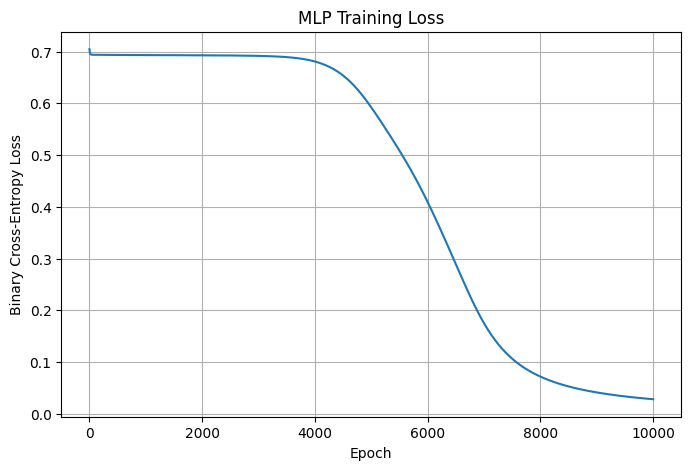

In [14]:
plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("MLP Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")

plt.grid(True)
plt.show()

In [15]:
# Generate predictions using trained parameters
Z1, A1, Z2, A2 = forward_propagation(
    X, W1, b1, W2, b2
)

# Convert probabilities into binary predictions
predictions = (A2 >= 0.5).astype(int)

print("Actual outputs:")
print(y.astype(int))

print("\nPredicted probabilities:")
print(A2)

print("\nPredicted outputs:")
print(predictions)

Actual outputs:
[[0]
 [1]
 [1]
 [0]]

Predicted probabilities:
[[0.03343862]
 [0.97440298]
 [0.97427182]
 [0.02651053]]

Predicted outputs:
[[0]
 [1]
 [1]
 [0]]


In [16]:
accuracy = np.mean(predictions == y) * 100

print(f"Training Accuracy: {accuracy:.2f}%")

Training Accuracy: 100.00%


# Results and Observations

After training, the model successfully learned the XOR input-output relationship.

The final predicted outputs matched all four actual XOR outputs.

Actual outputs:

``` [[0] [1] [1] [0]]```

Predicted outputs:

``` [[0] [1] [1] [0]]```

Training Accuracy: ``` 100% ```

The training loss decreased during the learning process, indicating that the network was improving its predictions.

# Points to Note

* The sigmoid function is useful for binary classification because it converts the network's output into a probability-like value between 0 and 1.
* We also used sigmoid in the hidden layer to introduce non-linearity.
* Backpropagation calculates the gradients; gradient descent uses them to update the parameters.